In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, KFold, GridSearchCV, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor

from sklearn.metrics import (
    mean_absolute_error,
    root_mean_squared_error,
    r2_score, 
    mean_squared_error
)

In [2]:
# configurations
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: f'{x:.3f}')
sns.set_theme(style='darkgrid')

plt.rcParams.update({
    'axes.titlesize': 10,
    'axes.labelsize': 9,
    'xtick.labelsize': 8,
    'ytick.labelsize': 8
})

RANDOM_STATE = 42
CSV_PATH = '../data/ford.csv'
TARGET_COL = 'price' # Target column name

Load Data

In [3]:
df = pd.read_csv(CSV_PATH)

In [4]:
df.shape

(17966, 9)

In [5]:
df.head()

,model,year,price,transmission,mileage,fuelType,tax,mpg,engineSize
0,Fiesta,2017,12000,Automatic,15944,Petrol,150,57.700,1.000
1,Focus,2018,14000,Manual,9083,Petrol,150,57.700,1.000
2,Focus,2017,13000,Manual,12456,Petrol,150,57.700,1.000
3,Fiesta,2019,17500,Manual,10460,Petrol,145,40.300,1.500
4,Fiesta,2019,16500,Automatic,1482,Petrol,145,48.700,1.000


In [6]:
categorical_cols = ['model', 'transmission', 'fuelType']

for col in categorical_cols:
    df[col] = (
        df[col]
        .astype('string')
        .str.strip()
        .str.lower()
    )

In [7]:
df.drop(df[df['year'] > 2026].index, inplace=True)

EDA

In [8]:
df.columns

Index(['model', 'year', 'price', 'transmission', 'mileage', 'fuelType', 'tax',
       'mpg', 'engineSize'],
      dtype='str')

In [9]:
df.info()

<class 'pandas.DataFrame'>
Index: 17965 entries, 0 to 17965
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   model         17965 non-null  string 
 1   year          17965 non-null  int64  
 2   price         17965 non-null  int64  
 3   transmission  17965 non-null  string 
 4   mileage       17965 non-null  int64  
 5   fuelType      17965 non-null  string 
 6   tax           17965 non-null  int64  
 7   mpg           17965 non-null  float64
 8   engineSize    17965 non-null  float64
dtypes: float64(2), int64(4), string(3)
memory usage: 1.7 MB


In [10]:
df.isna().sum()

model           0
year            0
price           0
transmission    0
mileage         0
fuelType        0
tax             0
mpg             0
engineSize      0
dtype: int64

In [11]:
# Check Presence of Encoded Missing Values
for col in df.columns:
    print(df[col].value_counts().head(20))

model
fiesta                   6556
focus                    4589
kuga                     2225
ecosport                 1143
c-max                     543
ka+                       531
mondeo                    526
b-max                     355
s-max                     296
grand c-max               247
galaxy                    228
edge                      208
ka                        199
puma                       80
tourneo custom             69
grand tourneo connect      59
mustang                    57
tourneo connect            33
fusion                     16
streetka                    2
Name: count, dtype: int64[pyarrow]
year
2017    4888
2018    4014
2019    3194
2016    2331
2015    1368
2014     805
2013     609
2020     258
2012     115
2011      94
2009      91
2010      67
2008      57
2007      32
2005      16
2006      13
2004       4
2002       3
2003       3
1998       1
Name: count, dtype: int64
price
10000    164
11000    153
10500    148
12000    126
9000     1

In [12]:
df.duplicated().sum()
df = df.drop_duplicates()
df.shape

(17811, 9)

In [13]:
numerical_cols = df.select_dtypes(include=[np.number]).columns.tolist()
categorical_cols = df.select_dtypes(include=['object', 'string', 'category']).columns.tolist()    

In [14]:
df[numerical_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
year,17811.000,2016.860,2.026,1996.000,2016.000,2017.000,2018.000,2020.000
price,17811.000,12269.881,4736.221,495.000,8999.000,11289.000,15295.000,54995.000
mileage,17811.000,23379.382,19418.128,1.000,10000.000,18274.000,31092.500,177644.000
tax,17811.000,113.310,62.033,0.000,30.000,145.000,145.000,580.000
mpg,17811.000,57.910,10.132,20.800,52.300,58.900,65.700,201.800
engineSize,17811.000,1.351,0.433,0.000,1.000,1.200,1.500,5.000


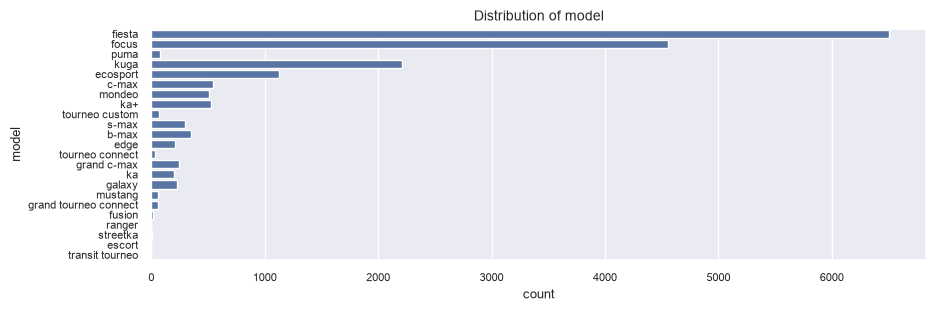

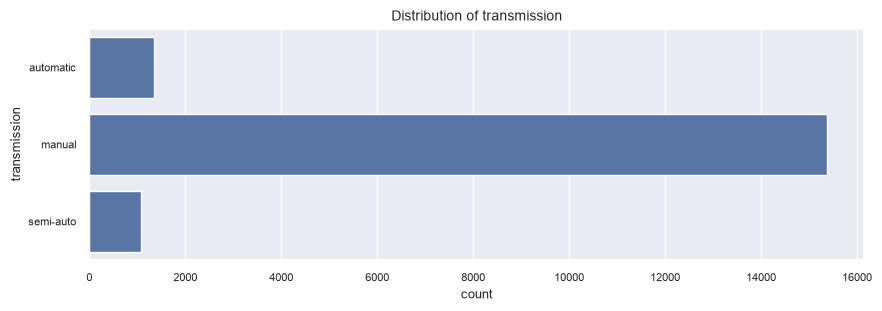

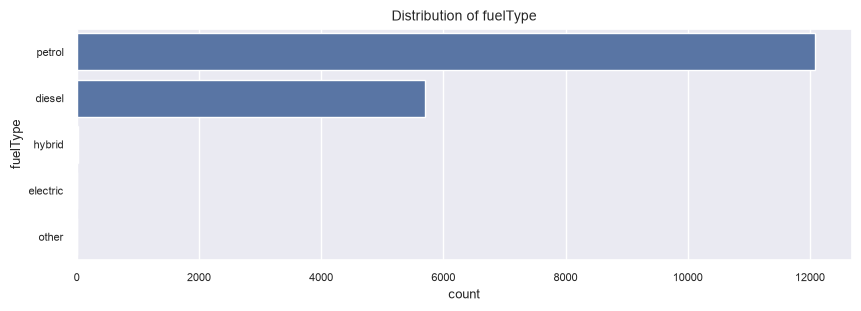

In [15]:
for col in categorical_cols:
    plt.figure(figsize=(10,3))
    sns.countplot(y=col, data=df)
    plt.title(f"Distribution of {col}")
    plt.show()

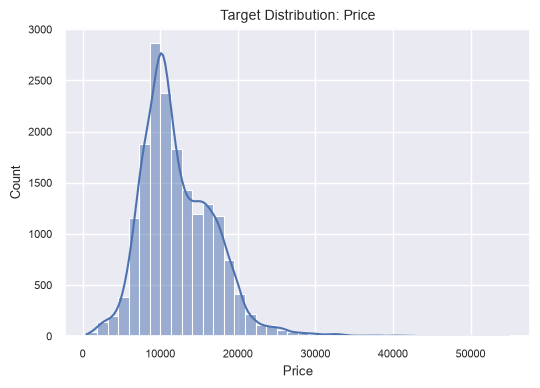

In [16]:
plt.figure(figsize=(6,4))
sns.histplot(df[TARGET_COL], bins=40, kde=True) # type: ignore
plt.title("Target Distribution: Price")
plt.xlabel("Price")
plt.show()

In [17]:
df[TARGET_COL].value_counts()

price
10000    164
11000    153
10500    146
12000    124
9000     117
        ... 
25050      1
13849      1
12849      1
16249      1
18122      1
Name: count, Length: 3511, dtype: int64

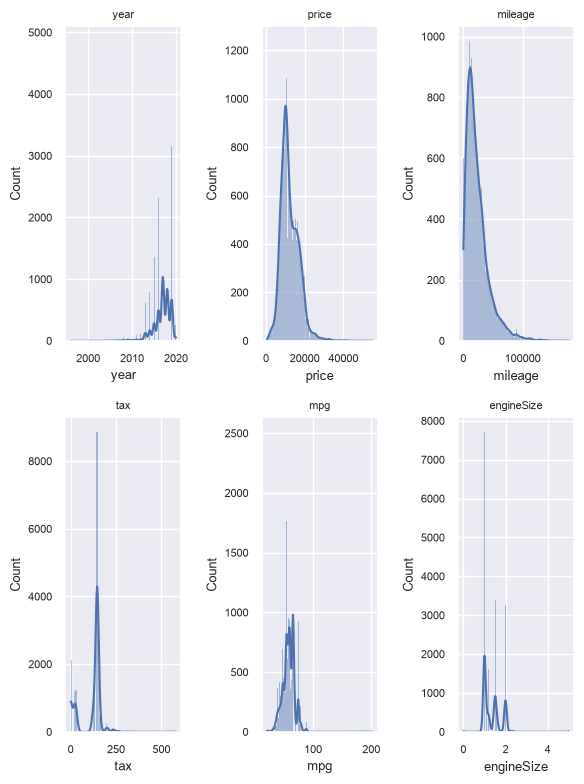

In [18]:
# histogram plot - distribution
fig, axes = plt.subplots(2,3,figsize=(6,8))
axes = axes.flatten()

for i, col in enumerate(numerical_cols):
    sns.histplot(df[col], kde=True, ax=axes[i]) # type: ignore
    axes[i].set_title(col, fontsize=8)
    
plt.tight_layout()
plt.show()

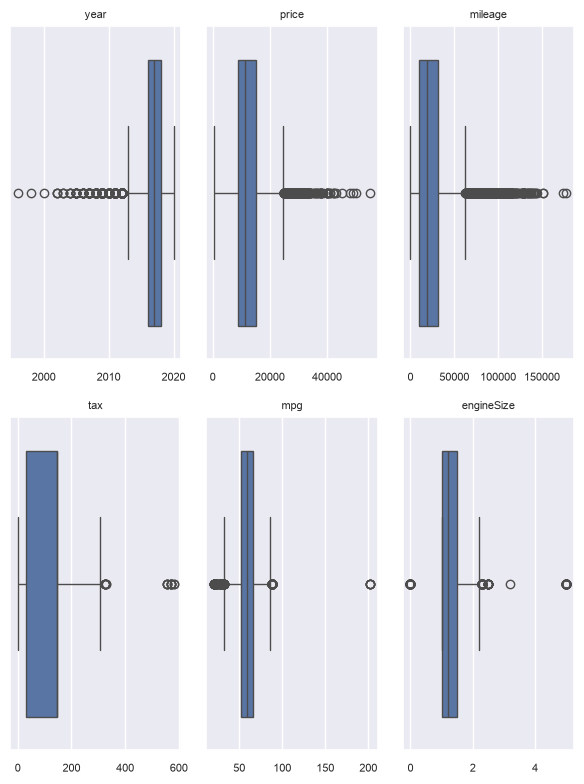

In [19]:
# outliers analysis - boxplot
fig, axes = plt.subplots(2,3,figsize=(6,8))
axes = axes.flatten()

for i, col in enumerate(numerical_cols):
    sns.boxplot(x = df[col], ax=axes[i])
    axes[i].set_title(col, fontsize=8)
    axes[i].set_xlabel("")
    
plt.tight_layout()
plt.show()

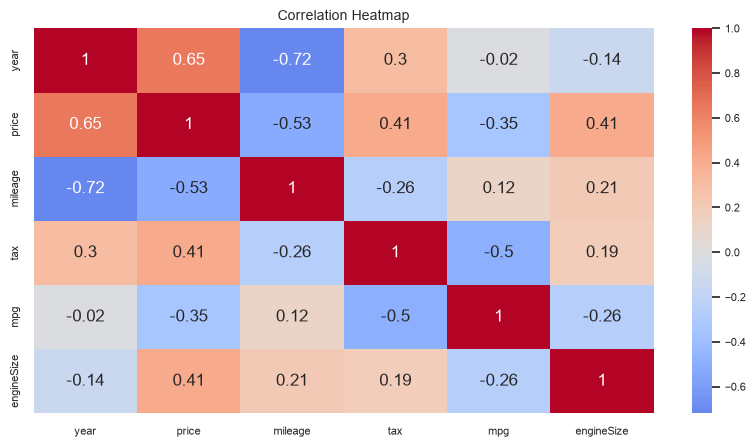

In [20]:
# Identify presence of highly correlated columns & feature relationships
plt.figure(figsize=(10,5))
sns.heatmap(
    df[numerical_cols].corr(),
    annot=True,
    cmap = 'coolwarm',
    center=0
)

plt.title(
'Correlation Heatmap'
)
plt.show()

In [21]:
# Correlation with Target
corr_with_target = df[numerical_cols].corr()[TARGET_COL].sort_values(ascending=False)
corr_with_target

price         1.000
year          0.645
engineSize    0.411
tax           0.406
mpg          -0.346
mileage      -0.530
Name: price, dtype: float64

Data Preprocessing

In [22]:
# Separating Features and Outcome
x = df.drop(columns=[TARGET_COL])
y = df[TARGET_COL]

In [23]:
x_train, x_test, y_train, y_test = train_test_split(x,y,test_size=0.2,random_state=RANDOM_STATE)

Preprocessing Pipeline

In [24]:
numerical_features = x_train.select_dtypes(include=[np.number]).columns.tolist()
categorical_features = x_train.select_dtypes(exclude=[np.number]).columns.tolist()

In [25]:
numerical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()) 
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False)) 
])

In [26]:
preprocess = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

BaseLine Model (No CV, No Tuning)

In [27]:
baseline_pipe = Pipeline(
    steps=[
        ('preprocess', preprocess),
        ('model', LinearRegression())
    ]
)

In [28]:
# Preprocess the data and train the baseline model
baseline_pipe.fit(x_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](8,)","['model','year','transmission',...,'tax','mpg','engineSize']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,8
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated

Evaluation of Baseline model

In [29]:
train_baseline_pred = baseline_pipe.predict(x_train)
test_baseline_pred = baseline_pipe.predict(x_test)

In [30]:
train_baseline_rmse = root_mean_squared_error(y_train, train_baseline_pred)
train_baseline_mae = mean_absolute_error(y_train, train_baseline_pred)
train_baseline_r2 = r2_score(y_train, train_baseline_pred)

print(f"RMSE: {train_baseline_rmse:.3f} \nMAE: {train_baseline_mae:.3f} \nR2: {train_baseline_r2:.3f}")

RMSE: 1848.503 
MAE: 1361.339 
R2: 0.847


In [31]:
test_baseline_rmse = root_mean_squared_error(y_test, test_baseline_pred)
test_baseline_mae = mean_absolute_error(y_test, test_baseline_pred)
test_baseline_r2 = r2_score(y_test, test_baseline_pred)

print(f"RMSE: {test_baseline_rmse:.3f} \nMAE: {test_baseline_mae:.3f} \nR2: {test_baseline_r2:.3f}")

RMSE: 1808.697 
MAE: 1351.265 
R2: 0.858


Model Selection & Optimization

In [32]:
# Models to try
models = {
    'LinearRegression': LinearRegression(),
    'Ridge': Ridge(random_state=RANDOM_STATE),
    'Lasso': Lasso(random_state=RANDOM_STATE, max_iter=10000),
    'RandomForestRegressor': RandomForestRegressor(),
    'HistGradientBoostingRegressor': HistGradientBoostingRegressor()
}

In [33]:
k = 5
cv = KFold(n_splits=k, shuffle=True, random_state=RANDOM_STATE)

In [34]:
scoring = {
    'rmse': 'neg_root_mean_squared_error',
    'mae': 'neg_mean_absolute_error',
    'r2': 'r2'
}

In [35]:
rows = []

for name, model in models.items():
    pipe = Pipeline(
        steps=[
            ('preprocess', preprocess),
            ('model', model)
        ]
    )
    scores = cross_validate(pipe, x_train, y_train, cv=cv, scoring=scoring, n_jobs=1)
    rows.append({
        'model': name,
        'cv_rmse': -scores['test_rmse'].mean(),
        'cv_mae': -scores['test_mae'].mean(),
        'cv_r2': scores['test_r2'].mean(),
    })
    
# sort based on low rmse values
cv_results = pd.DataFrame(rows).sort_values('cv_rmse')
print(cv_results)

                           model  cv_rmse   cv_mae  cv_r2
4  HistGradientBoostingRegressor 1220.033  832.238  0.933
3          RandomForestRegressor 1291.039  884.114  0.925
1                          Ridge 1859.542 1366.170  0.845
0               LinearRegression 1859.749 1366.473  0.844
2                          Lasso 1860.458 1366.629  0.844


In [36]:
best_row = cv_results.sort_values('cv_rmse').iloc[0]
best_model_name = best_row['model']
best_rmse = best_row['cv_rmse']

Hyperparameter Tuning

In [37]:
high_pipe = Pipeline(
    steps=[
        ('preprocess', preprocess),
        ('model', HistGradientBoostingRegressor(random_state=RANDOM_STATE))
    ]
)

In [38]:
# hyperparameter combinations
param_grid = {
    'model__learning_rate': [0.03,0.05,0.1],
    'model__max_depth': [None,3,6],
    'model__max_leaf_nodes': [15,31,63],
    'model__min_samples_leaf': [20,50,100],
    'model__l2_regularization': [0.0,0.1,1.0]
}

In [39]:
grid = GridSearchCV(
    estimator=high_pipe,
    param_grid=param_grid,
    cv=cv,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1, # for parallel execution
    verbose=1
)

In [40]:
grid.fit(x_train,y_train)

Fitting 5 folds for each of 243 candidates, totalling 1215 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__l2_regularization': [0.0, 0.1, ...], 'model__learning_rate': [0.03, 0.05, ...], 'model__max_depth': [None, 3, ...], 'model__max_leaf_nodes': [15, 31, ...], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_root_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.S

In [41]:
grid.best_params_

{'model__l2_regularization': 0.1,
 'model__learning_rate': 0.1,
 'model__max_depth': None,
 'model__max_leaf_nodes': 63,
 'model__min_samples_leaf': 20}

In [42]:
best_hgb_params = {
    name.split('__', maxsplit=1)[1]: value
    for name, value in grid.best_params_.items()
}

hgb_best = Pipeline(
    steps=[
        ('preprocess', preprocess),
        ('model', HistGradientBoostingRegressor(
            random_state=RANDOM_STATE,
            **best_hgb_params
        ))
    ]
)

In [43]:
hgb_best.fit(x_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](8,)","['model','year','transmission',...,'tax','mpg','engineSize']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,8
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated

In [44]:
train_final_pred = hgb_best.predict(x_train)

train_final_rmse = root_mean_squared_error(y_train, train_final_pred)
train_final_mae = mean_absolute_error(y_train, train_final_pred)
train_final_r2 = r2_score(y_train, train_final_pred)

print(f"RMSE: {train_final_rmse}\nMAE: {train_final_mae}\nR2: {train_final_r2}")

RMSE: 1019.9441900125208
MAE: 720.6803184650943
R2: 0.9533292029816692


In [45]:
test_final_pred = hgb_best.predict(x_test)

test_final_rmse = root_mean_squared_error(y_test, test_final_pred)
test_final_mae = mean_absolute_error(y_test, test_final_pred)
test_final_r2 = r2_score(y_test, test_final_pred)

print(f"RMSE: {test_final_rmse}\nMAE: {test_final_mae}\nR2: {test_final_r2}")

RMSE: 1133.0022900393387
MAE: 809.9786544615197
R2: 0.9441578410058048


In [46]:

def predict_ford_price(
    ai_model,
    model: str,
    year: int,
    transmission: str,
    mileage: int,
    fuelType: str,
    tax: int,
    mpg: float,
    engineSize: float
) -> int:
    """Predict price for one Ford car."""

    new_row = pd.DataFrame([{
        'model': str(model).strip().lower(),
        'year': year,
        'transmission': str(transmission).strip().lower(),
        'mileage': mileage,
        'fuelType': str(fuelType).strip().lower(),
        'tax': tax,
        'mpg': mpg,
        'engineSize': engineSize
    }])

    return int(round(float(ai_model.predict(new_row)[0])))


# Example inference
example_pred = predict_ford_price(
    ai_model=hgb_best,
    model='Fiesta',
    year=2012,
    transmission='Automatic',
    mileage=10000,
    fuelType='Diesel',
    tax=125,
    mpg=57.7,
    engineSize=1.5
)

print(f"Predicted Ford car price: £{example_pred:,}")


Predicted Ford car price: £8,030


In [47]:
example_pred

8030

In [48]:
# ==========================================
# TEST SET PREDICTIONS
# ==========================================

test_predictions = hgb_best.predict(x_test)

results_with_cars = x_test.copy()

results_with_cars['Actual Price'] = y_test.values
results_with_cars['Predicted Price'] = test_predictions

results_with_cars['Error'] = (
    results_with_cars['Actual Price']
    - results_with_cars['Predicted Price']
)

results_with_cars['Absolute Error'] = (
    results_with_cars['Error'].abs()
)

actual_prices = results_with_cars['Actual Price'].replace(0, np.nan)

results_with_cars['Percentage Error'] = (
    results_with_cars['Absolute Error'].div(actual_prices) * 100
)


# Show first 10 predictions
results_with_cars.head(10)

,model,year,transmission,mileage,fuelType,tax,mpg,engineSize,Actual Price,Predicted Price,Error,Absolute Error,Percentage Error
1034,galaxy,2017,manual,50565,diesel,150,56.500,2.000,14995,15518.310,-523.310,523.310,3.490
16978,focus,2005,manual,87530,petrol,235,39.800,2.000,2295,2894.975,-599.975,599.975,26.143
2864,focus,2016,manual,13820,petrol,200,41.500,2.000,14950,16701.552,-1751.552,1751.552,11.716
11569,focus,2017,manual,26181,petrol,145,41.500,2.000,17890,16615.031,1274.969,1274.969,7.127
10089,focus,2018,manual,26500,petrol,150,60.100,1.000,11795,11720.046,74.954,74.954,0.635
11049,fiesta,2015,manual,33000,petrol,0,65.700,1.000,8263,7692.326,570.674,570.674,6.906
15446,fiesta,2016,manual,32737,petrol,0,65.700,1.000,8000,8065.743,-65.743,65.743,0.822
2314,kuga,2019,manual,10465,diesel,145,37.700,2.000,20500,21304.275,-804.275,804.275,3.923
17894,c-max,2016,automatic,26077,diesel,20,64.200,1.500,10999,9852.888,1146.112,1146.112,10.420
13953,ecosport,2018,manual,16299,petrol,145,54.300,1.000,15000,13397.436,1602.564,1602.564,10.684


In [49]:
# ==========================================
# WORST PREDICTIONS
# ==========================================

worst_predictions = results_with_cars.sort_values(
    by='Absolute Error',
    ascending=False
)

worst_predictions.head(10)

,model,year,transmission,mileage,fuelType,tax,mpg,engineSize,Actual Price,Predicted Price,Error,Absolute Error,Percentage Error
2011,focus,2018,manual,13847,petrol,145,58.900,1.000,25998,13626.230,12371.770,12371.770,47.587
16906,mondeo,2008,manual,1,diesel,200,47.900,2.000,1299,8987.060,-7688.060,7688.060,591.845
10958,focus,2020,automatic,10,petrol,145,39.800,1.500,30999,23508.261,7490.739,7490.739,24.164
17236,kuga,2018,automatic,21516,diesel,140,54.300,2.000,24995,18138.972,6856.028,6856.028,27.430
13283,focus,2019,automatic,6000,petrol,145,51.400,1.000,23990,17235.376,6754.624,6754.624,28.156
508,tourneo custom,2019,manual,5100,diesel,145,31.700,2.000,20990,27648.424,-6658.424,6658.424,31.722
2468,focus,2019,automatic,3541,diesel,145,74.300,1.500,23695,18063.174,5631.826,5631.826,23.768
16332,focus,2018,manual,19000,petrol,145,67.300,0.000,18389,13089.006,5299.994,5299.994,28.822
354,mustang,2018,automatic,6250,petrol,145,23.500,5.000,31498,36540.589,-5042.589,5042.589,16.009
11001,fiesta,2020,manual,12,petrol,145,40.400,1.500,25999,21097.105,4901.895,4901.895,18.854


In [50]:
# ==========================================
# BEST PREDICTIONS
# ==========================================

best_predictions = results_with_cars.sort_values(
    by='Absolute Error',
    ascending=True
)

best_predictions.head(10)

,model,year,transmission,mileage,fuelType,tax,mpg,engineSize,Actual Price,Predicted Price,Error,Absolute Error,Percentage Error
3402,ecosport,2019,semi-auto,5964,petrol,150,44.100,1.000,17480,17479.953,0.047,0.047,0.000
10134,fiesta,2014,manual,33458,petrol,0,65.700,1.000,7299,7298.891,0.109,0.109,0.001
11937,b-max,2014,manual,38200,petrol,30,57.700,1.000,7300,7299.191,0.809,0.809,0.011
14512,focus,2016,manual,100000,diesel,20,70.600,2.000,7793,7791.967,1.033,1.033,0.013
14522,focus,2016,manual,106000,diesel,20,70.600,2.000,7793,7791.967,1.033,1.033,0.013
1714,focus,2015,manual,37750,diesel,20,67.300,1.600,8998,8999.112,-1.112,1.112,0.012
1127,focus,2018,manual,9713,petrol,145,58.900,1.000,14300,14301.249,-1.249,1.249,0.009
15942,focus,2016,manual,66442,diesel,0,74.300,1.500,7999,8002.545,-3.545,3.545,0.044
5492,fiesta,2018,manual,15539,petrol,145,65.700,1.000,10991,10987.183,3.817,3.817,0.035
4101,focus,2017,manual,22158,petrol,20,60.100,1.000,10890,10886.125,3.875,3.875,0.036


In [51]:
mape = results_with_cars['Percentage Error'].mean()

print(f"Mean Absolute Percentage Error (MAPE): {mape:.2f}%")

Mean Absolute Percentage Error (MAPE): 6.95%


In [52]:
# joblib.dump(hgb_best, "ford_price_model.pkl")